In [2]:
import numpy as np
import matplotlib.pyplot as plt
from utils import *
import copy

# Data Augmentation

As a final regularization technique, we want to implement data augmentation. We will rotate (and translate?) the images in our dataset to increase the number of samples by a certain multiplier.

Nielsen talked about a kind of augmentation called elastic deformation. Would be cool to have something like that as well. 

We'll start with a small network (30 neurons in the hidden layer) and see how increasing the multiplier of the reduced data helps in training. First without L2 regularization and then with some adaptive lambda that scales with the amount of data that the network is being trained on. 

shape of raw training inputs x:  (50000, 784) 
shape of raw training labels y:  (50000,)


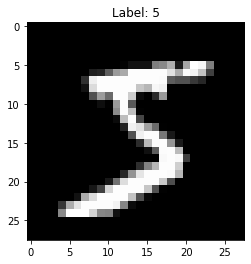

shape of x_train : (784, 50000)
shape of y_train : (10, 50000)


In [3]:
import pickle
import gzip

with gzip.open('neural-networks-and-deep-learning-master/data/mnist.pkl.gz', 'rb') as f:
    training_data, validation_data, test_data = pickle.load(f, encoding='latin1')

print('shape of raw training inputs x: ',training_data[0].shape, '\nshape of raw training labels y: ', training_data[1].shape)   # (50000, 784) (50000,)

first_image = training_data[0][0]
first_label = training_data[1][0]

# Reshape the first image to 28x28 pixels
image = first_image.reshape(28, 28)

# Display the image
plt.imshow(image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()

# Extract labels and training images from training_data
y_labels = training_data[1]
x_train = training_data[0].T

# Extract validation data
y_labels_val = validation_data[1]
x_val = validation_data[0].T

print('shape of x_train :',x_train.shape) # (728, 50000)
d = len(y_labels)

y_train = labels_to_onehot(y_labels)
y_val = labels_to_onehot(y_labels_val)

print('shape of y_train :',y_train.shape) # (728, 50000)

# Organize training data
train_data = (x_train, y_train)
val_data = (x_val, y_val)

Initialize a small network with ReLU activations

In [4]:
spec = [784, 30, 10]
act, del_act = [ReLU], [del_ReLU]

net = network(spec, activation=act, del_activation=del_act) 

# Compute initial accuracy of the network
print('initial accuracy', compute_accuracy(net, x_train, train_data[1]))

initial accuracy 0.034204


Function to augment the dataset

(2, 784)
[[15 15 15 ... 42 42 42]
 [15 16 17 ... 40 41 42]]


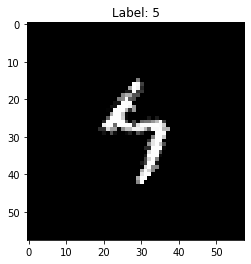

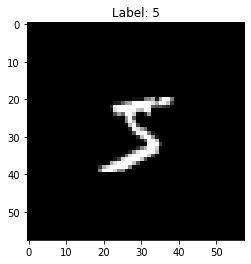

In [57]:
def pad_image(img, padding):
    ''' 
    pads the image with zeros. returns an array of the form (28 + 2 * padding, 28 + 2 * padding) where the original image can be recovered as 
    img = padded_image[padding:-padding, padding:-padding]
    '''
     
    padded_image = np.zeros((28 + 2 * padding, 28 + 2* padding, img.shape[2]))
    padded_image[padding:-padding, padding:-padding] = img
    return padded_image

def pixel_to_cartesian(pixel_coords, padding):
    '''
    transforms from pixel to cartesian coordinates
    [i,j] -> [j, L - i]
    '''
    cartesian = np.zeros_like(pixel_coords)
    cx = pixel_coords[1]
    cy =  28 + 2 * padding - pixel_coords[0] 

    cartesian[0] = cx
    cartesian[1] = cy

    return cartesian

def cartesian_to_pixel(cartesian_coords, padding):
    ''' 
    Transforms from cartesian to pixel coordinates
    [cx, cy] -> [L - cy, cx]
    '''
    pixel = np.zeros_like(cartesian_coords)
    px = 28 + 2 * padding - cartesian_coords[1]
    py =  cartesian_coords[0] 

    pixel[0] = px
    pixel[1] = py

    return pixel 

# Find rotation matrix 
theta = 45 
theta_rad = np.pi * theta / 180
sin = np.sin(theta_rad)
cos = np.cos(theta_rad)
rotmat = np.array([[cos, -sin],
                    [sin, cos]]) 

# Generate pixel coordinate grid where the rotated image will sit  
image = np.reshape(image, (28, 28, 1))
padding = 15 
padded_image = pad_image(image, padding)
r = np.arange(padding, 28 + padding)

i, j = np.meshgrid(r, r, indexing='ij')

coords = np.array([i.flatten(), j.flatten()])


center = np.array([[padding + 13],
                   [padding + 13]])
 

print(coords.shape)
print(coords)

cartesian_coords = pixel_to_cartesian(coords, padding)
center = np.array([[padding + 13],
                   [padding + 13]])
 
cartesian_center = pixel_to_cartesian(center, padding)

rot_coords = rotmat.T @ cartesian_coords
rot_center = rotmat.T @ cartesian_center

cartesian_transformed = cartesian_center - rot_center + rot_coords

idxs = np.round(cartesian_to_pixel(cartesian_transformed, padding)).astype(int)

rot_img = np.zeros_like(padded_image)
rot_img[coords[0], coords[1]] = padded_image[idxs[0], idxs[1]]


plt.imshow(rot_img, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()


plt.imshow(padded_image, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()







(784, 50000)


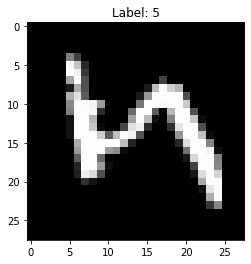

In [60]:
def rotate_image(x, theta, padding=15):
    ''' 
    rotates an image img by an angle theta. 

    - x is an array of shape (784, d) that contains a flattened MNIST image of a handwritten digit of size 784
    - theta is the angle in degrees at which the image is to be rotated
    '''

    # Bring image to matrix form and pad around it with zeros
    d = x.shape[1] 
    img_mat = np.reshape(x, (28, 28, d))
    pad_img = pad_image(img_mat, padding=padding) # (36, 36, d)

    # Find rotation matrix 
    theta_rad = np.pi * theta / 180
    sin = np.sin(theta_rad)
    cos = np.cos(theta_rad)
    rotmat = np.array([[cos, -sin],
                       [sin, cos]]) 

    # Find center of the grid
    c = np.array([[padding + 13.5],
                  [padding + 13.5]])

    # Find array of coordinates where the image is going to be sitting
    r = np.arange(padding, 28 + padding)

    i, j = np.meshgrid(r, r, indexing='ij')

    coords = np.array([i.flatten(), j.flatten()])

    cartesian_coords = pixel_to_cartesian(coords, padding)
    
    cartesian_center = pixel_to_cartesian(c, padding)

    rot_coords = rotmat.T @ cartesian_coords
    rot_center = rotmat.T @ cartesian_center

    cartesian_transformed = cartesian_center - rot_center + rot_coords

    idxs = np.round(cartesian_to_pixel(cartesian_transformed, padding)).astype(int)

    return pad_img[idxs[0], idxs[1]]




rt = rotate_image(x_train, 20)
print(np.shape(rt))
rt = rt[:,0]
img = np.reshape(rt, (28, 28))

plt.imshow(img, cmap='gray')
plt.title(f"Label: {first_label}")
plt.show()




In [61]:
def augment_data(data, mult, angle_range=[20, -20]):
    '''
    augments the training data via rotations. For each image, we will rotate the image from angle_range[0] deg to angle_range[1] in mult angular steps of size dtheta = 1/mult 

    ''' 
    x = data[0]
    y = data[1]
    d = x.shape[1]

    if mult == 0:
        return data
    
    angles = np.linspace(angle_range[0], angle_range[1], mult)

    x_aug = x # (784, d)
    y_aug = y # (10, d)

    for theta in angles:
        rotated_xs = rotate_image(x, theta, padding=20) # (784, d)
        x_aug = np.append(x_aug, rotated_xs, axis=1) 
        y_aug = np.append(y_aug, y, axis=1)

    return (x_aug, y_aug)
        


In [56]:
x = train_data[0]

x_rot = rotate_image(x, 0, padding=20)

print(x.shape == x_rot.shape)
print(np.max(np.abs(x - x_rot)))

True
0.99609375


Create an experiment loop with different data multiplicities m 

m =  0
training examples : 1000
Initial Training Loss 2.3419047705780227


100%|██████████| 400/400 [01:41<00:00,  3.93it/s]


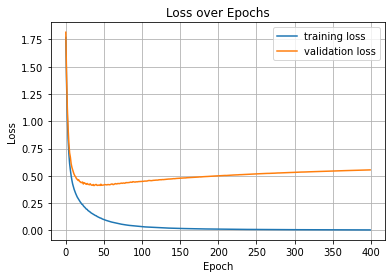

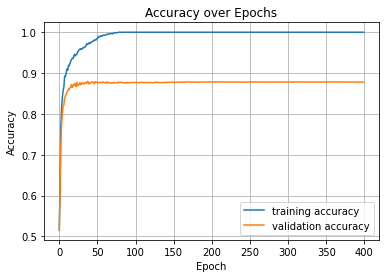

accuracy for mult = 0 : 0.8781
m =  1
training examples : 2000
Initial Training Loss 2.3648881362188967


100%|██████████| 200/200 [00:46<00:00,  4.26it/s]


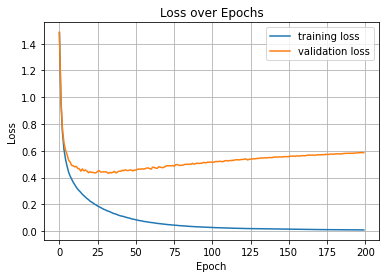

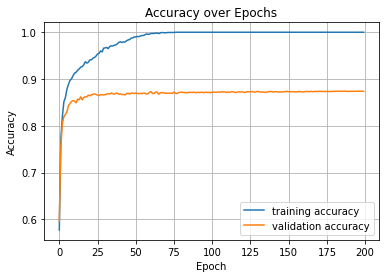

accuracy for mult = 1 : 0.8737
m =  2
training examples : 3000
Initial Training Loss 2.3437964865579954


100%|██████████| 133/133 [00:35<00:00,  3.71it/s]


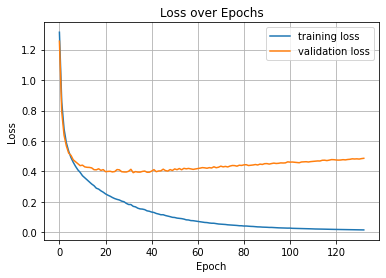

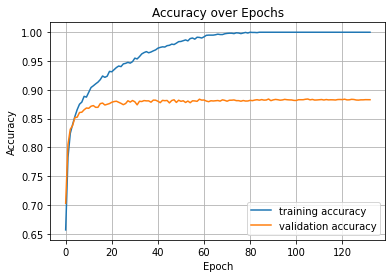

accuracy for mult = 2 : 0.8828
m =  3
training examples : 4000
Initial Training Loss 2.343323557563002


100%|██████████| 100/100 [00:29<00:00,  3.40it/s]


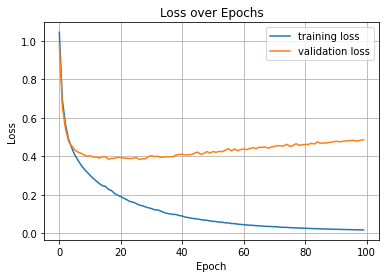

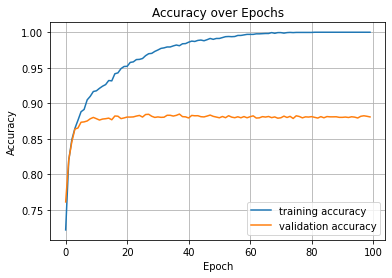

accuracy for mult = 3 : 0.8807
m =  4
training examples : 5000
Initial Training Loss 2.345761945697049


100%|██████████| 80/80 [00:28<00:00,  2.85it/s]


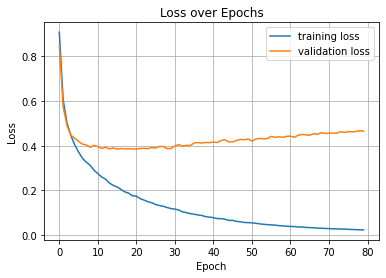

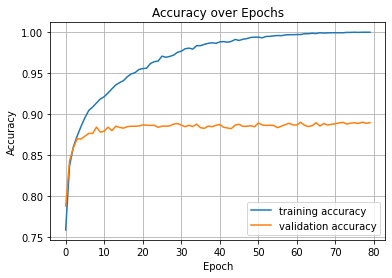

accuracy for mult = 4 : 0.8895
m =  5
training examples : 6000
Initial Training Loss 2.3430107141519123


100%|██████████| 66/66 [00:21<00:00,  3.09it/s]


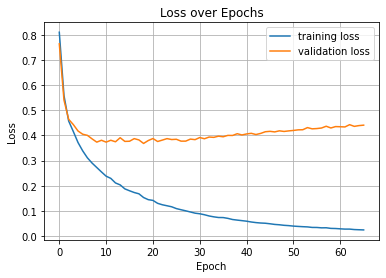

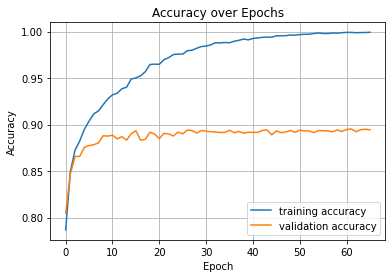

accuracy for mult = 5 : 0.8944
m =  6
training examples : 7000
Initial Training Loss 2.342829364301366


100%|██████████| 57/57 [00:20<00:00,  2.79it/s]


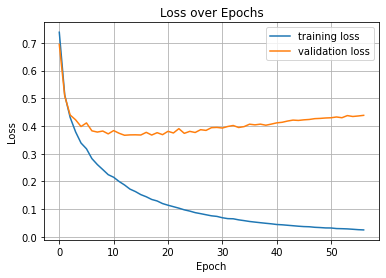

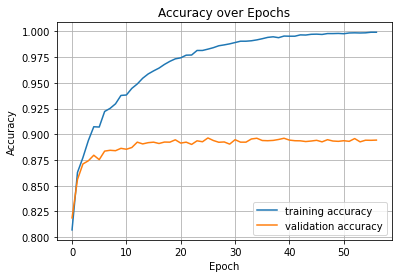

accuracy for mult = 6 : 0.8943
m =  7
training examples : 8000
Initial Training Loss 2.343829263632609


100%|██████████| 50/50 [00:18<00:00,  2.73it/s]


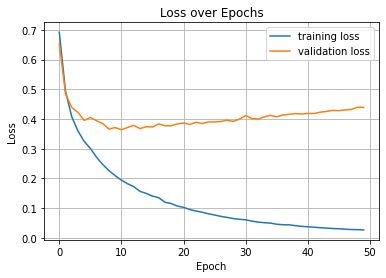

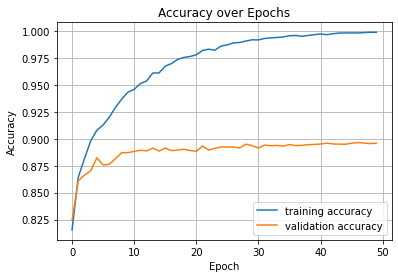

accuracy for mult = 7 : 0.8959
m =  8
training examples : 9000
Initial Training Loss 2.342529799326484


100%|██████████| 44/44 [00:18<00:00,  2.32it/s]


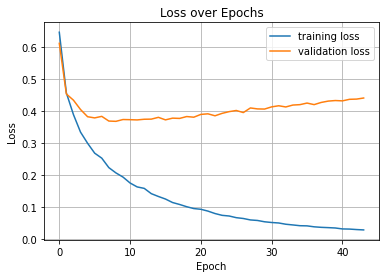

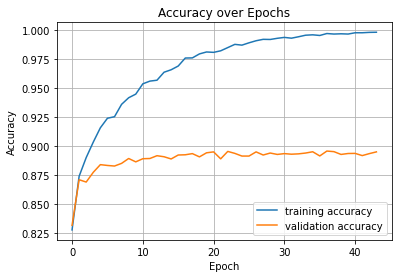

accuracy for mult = 8 : 0.8948
[0.8781 0.8737 0.8828 0.8807 0.8895 0.8944 0.8943 0.8959 0.8948]


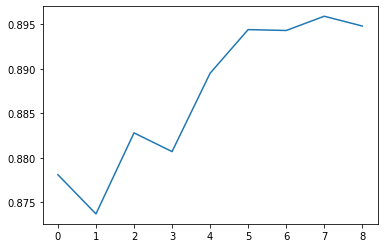

In [65]:
epochs = 400
eta = 0.05
ms = [0, 1, 2, 3, 4, 5, 6, 7, 8]
lam=0
accuracies = np.zeros(len(ms))

# Just include first 1000 samples in training
reduced_train_data = (x_train[:,:1000], y_train[:,:1000])

# Same initialization -> Same initial condition

for i in range(len(ms)):
    Ni = copy.deepcopy(net) 
    epochs_i = int(epochs / (ms[i] + 1))
    augmented_data = augment_data(reduced_train_data, ms[i], angle_range=[20,-20])
    print('m = ', ms[i])
    print('training examples :', augmented_data[0].shape[1])
    Ni, train_losses, val_losses, train_acc, val_acc = train(Ni, augmented_data, val_data, epochs=epochs_i, eta=eta, verbose=False, lam=lam, p_drop=0)
    plot_loss(train_losses, val_losses)
    plot_accuracies(train_acc, val_acc)
    accuracies[i] = compute_accuracy(Ni, x_val, y_labels_val)
    print('accuracy for mult =', ms[i], ':', accuracies[i])

print(accuracies)

plt.figure()
plt.plot(ms, accuracies)

Now we can try to have a bigger network with L2 regularization and data augmentation: 

This should in principle be a clean comparison with the trials in overfitting.ipynb. Here, we rescale the number of epochs according to the augmentation multiplier of our data to have the same compute budget (number of gradient steps) as in the experiment with only L2 regularization. Because of the augmented numer of training examples, we also need to scale the regularization parameter lambda accordingly. We use the multiplier that was found optimal in earlier experiments when having no regularization and angular range 15 to -15 degrees. 

In [67]:
deep_spec = [784, 256, 64, 10]
act = [ReLU]
del_act = [del_ReLU]

deep_net = network(deep_spec, act, del_act)

initial_accuracy = compute_accuracy(deep_net, x_train, training_data[1])
print('Initial accuracy of the deep net', initial_accuracy)

Initial accuracy of the deep net 0.08768


Initial Training Loss 2.4413010501971


100%|██████████| 20/20 [06:12<00:00, 18.65s/it]


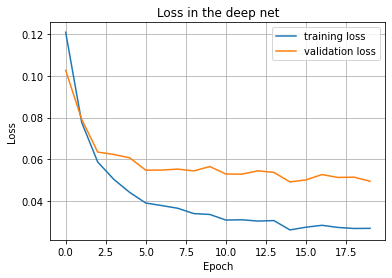

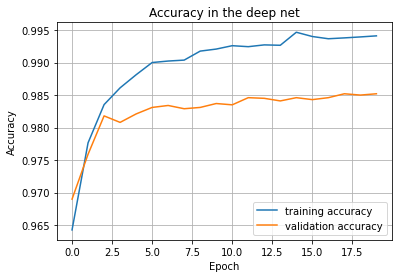

Final validation accuracy in the deep net : 98.52 %


In [69]:
mult = 4
trained_deep_net = copy.deepcopy(deep_net) 
train_data_aug = augment_data(train_data, mult, angle_range=[15,-15])
lam = 25 * (mult + 1)
epochs = 100 // (mult + 1)


trained_deep_net, train_losses_deep, val_losses_deep, train_acc_deep, val_acc_deep = train(trained_deep_net, train_data_aug, val_data, epochs=epochs, eta=eta, verbose=False, lam=lam)
plot_loss(train_losses_deep, val_losses_deep, title='Loss in the deep net')
plot_accuracies(train_acc_deep, val_acc_deep, title='Accuracy in the deep net')
print('Final validation accuracy in the deep net :',val_acc_deep[-1] * 100, '%')

We see that we get 98.52 % in the case of augmented data instead of 98.24 % in the case of unaugmented data using the same compute budget as before. However, we note that we are far from saturation in the augmented validation accuracy, so we can try to increase the number of epochs to say, 50, and see what the validation accuracy at saturation is.  

Initial Training Loss 2.4413010501971


100%|██████████| 50/50 [16:07<00:00, 19.36s/it]


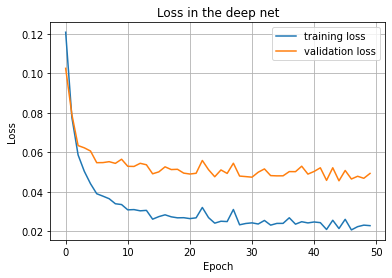

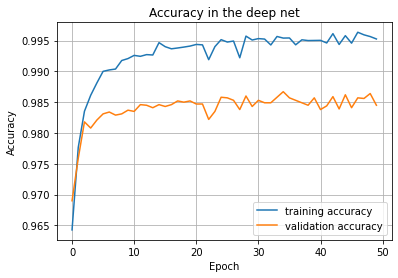

Final validation accuracy in the deep net : 98.45 %


In [70]:
mult = 4
trained_deep_net_2 = copy.deepcopy(deep_net) 
lam = 25 * (mult + 1)
epochs = 50 


trained_deep_net_2, train_losses_deep, val_losses_deep, train_acc_deep, val_acc_deep = train(trained_deep_net_2, train_data_aug, val_data, epochs=epochs, eta=eta, verbose=False, lam=lam)
plot_loss(train_losses_deep, val_losses_deep, title='Loss in the deep net')
plot_accuracies(train_acc_deep, val_acc_deep, title='Accuracy in the deep net')
print('Final validation accuracy in the deep net :',val_acc_deep[-1] * 100, '%')

Actually, it was better before. We don't saturate to a narrow value but rather fluctuate around 98.5% with an ampliture of 0.1 %